# §9 Citation returns to reported compute

Do papers that report more accelerator capacity get cited more, conditional on
field and year? The estimating equation, for paper $i$ in field $f$ and year $t$:

$$\log(1 + c_{i}^{3}) = \beta \cdot \log_2(\text{capacity}_i) + \alpha_f + \gamma_t + \varepsilon_i$$

where $c_i^3$ is 3-year forward citations (`i_3`, cumulative citations three
years post-publication from the release's own citation graph) and capacity is
either reported FP32 GFLOPS or reported VRAM GB. Estimation is **pyfixest**
(`pf.feols`, `pf.fepois`); `accelscan.regress` holds only the polars hand-off,
result tidying, and one guard described in §9.5.

**Why $\log_2$ of capacity, not the level.** Reported capacity spans seven
orders of magnitude (FP32: 21 GFLOPS to 175 PFLOPS) and is right-skewed by
construction — it is a product of a device count and a per-device spec, both
skewed. A coefficient on the level would be a coefficient on the tail: the top
0.1% of papers would move it, and "one more GB" means something entirely
different at 8 GB than at 1,280 GB. On $\log_2$, $\beta$ is the change in
log(1+citations) **per doubling of capacity**, which is the unit the hardware
actually comes in (generations double, they do not add GB). §9.3 nonetheless
reports the level specification the per-GB reading asks for, on a trimmed
sample and with its leverage stated, plus a standardized (per-SD) version;
§9.4 drops the functional form entirely and estimates the dose-response
nonparametrically, which is the real test of whether the log form is adequate.

**Reading the coefficients in citations.** The outcome stays `log1p` — that is
the regressand in every specification — but the figures' axes are *relabelled*
into citations, since "0.11 log points" is not a quantity anyone has intuition
for. The conversion (`regress.delta_citations`) is

$$\Delta c = (1 + \bar{c})\,(e^{\beta} - 1)$$

evaluated at a stated baseline $\bar{c}$, the **median** `i_3` of the relevant
sample. It is exact for a paper sitting at that baseline and monotone in $\beta$
(so a confidence interval maps to its image, and axis ticks map to a valid
second axis), but it is *not* an average effect across the sample: the effect is
proportional, so a 200-citation paper gains far more than a 5-citation one. The
baseline is printed next to every figure and table that uses it.

**One thing the year effects settle.** With year fixed effects, "absolute
capacity" and "distance to the year's vendor frontier" are the *same regressor*:
the frontier is constant within a year, so $\log_2(\text{cap}_i) -
\log_2(\text{frontier}_t)$ differs from $\log_2(\text{cap}_i)$ by a year
constant that $\gamma_t$ absorbs. Every $\beta$ below is therefore already a
within-year, frontier-relative estimate, and no separate "gap to frontier"
specification is needed.

> **This is a descriptive conditional association, not a causal effect of
> compute.** Capacity is chosen, and it is chosen by better-resourced authors at
> better-resourced institutions working on more visible problems, all of which
> independently predict citations. §9.7 shows how much of $\beta$ survives
> controls for team size and reference count — some, not all — and that is a
> bound on the confounding it can address, not a solution to it. Read $\beta$ as
> "papers reporting twice the capacity are cited $x\%$ more than same-field,
> same-year papers", full stop.

> **Capacity is reported NAMEPLATE PEAK, not utilized FLOPs** — the same caveat
> that governs every figure in §5. It measures the compute a paper had and chose
> to report.

*arXiv is absent by construction: it has no citation outcome. The arXiv corpus
carries no Semantic Scholar identifier crosswalk (a locked design decision), so
`analytic/.../citations.parquet` exists for S2ORC only and this analysis is
single-corpus.*

In [1]:
import os

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyfixest as pf
from accelscan import regress as rg
from accelscan.config import BUCKET, PAPERS_PREFIX
from accelscan.paths import analytic_base, capacity_key, get_corpus, s3_uri
from accelscan.plotting import setup_figures
from accelscan.registry import load_registry
from accelscan.s3 import storage_options

# integer year ticks + every figure exported to output/analysis/citations/
setup_figures('citations')

## Knobs

In [2]:
CORPUS = 's2orc'             # arXiv has no citation outcome (see the note above)
COUNT_POLICY = 'floor1'      # 'floor1' (primary) | 'explicit' (robustness, §9.8)
MODEL_TAG, PROMPT_VERSION = 'qwen3-14b', 'p1'
OUTCOME = 'i_3'              # 3-year forward citations
YEAR_MIN = 2010
# i_3 needs three full post-publication years. The outcomes table is built from
# the 2026-07-28 release's citation graph, so 2022 is the last year whose window
# is closed; 2023+ would mix complete and truncated windows within the same year
# effect, which biases the level, not just the precision.
YEAR_MAX = 2022
TOP_FIELDS = 8               # fields ranked by papers with ANY accelerator mention
MIN_YEAR_N = 300             # flag year slopes resting on fewer papers than this
TRIM_Q = 0.99                # level specs (§9.3) drop above this capacity quantile
N_BINS = 12                  # dose-response bins (§9.4)
WITH_CONTROLS = True         # fetch referencecount / author count from the papers table

# One range for BOTH heterogeneity figures: §9.5 plots slopes on x, §9.6 plots
# the same quantity on y, so a shared range makes the two directly comparable by
# eye (field spread vs time spread). Held in log points because that is the unit
# the coefficients and their CIs come in, and asserted against in both cells so
# widening is a loud failure rather than a silent clip. Those figures are drawn
# in citations, on its image `CITE_LIM` -- the conversion is monotone, so the two
# ranges are the same range in two units.
SLOPE_LIM = (-0.08, 0.33)

FE = 'field + year_f'        # additive field + year effects: the primary spec
CL = {'CRV1': 'field'}       # cluster on field (see the note in §9.2)
# Interaction specifications (§9.5, §9.6) must cluster FINER than the group they
# interact with, or the SEs are numerical noise. `regress.assert_cluster_finer`
# is called before each one; §9.5 explains why.
CL_INT = {'CRV1': 'field_year'}

C_FP32, C_VRAM, C_DEV = '#0072B2', '#009E73', '#CC79A7'
c = get_corpus(CORPUS)
reg = load_registry()
so = storage_options()
KEY = c.key

## Load: capacity x citations x field

Three tables, all already built by the pipeline:

- `capacity/.../paper_capacity_{policy}.parquet` — per-paper reported capacity
  (stage 3.5), the regressors.
- `analytic/.../citations.parquet` — `i_2`/`i_3`/`citations_5y` per focal paper
  (stage 4a), the outcome.
- the papers metadata parquet — `s2fieldsofstudy` for the field effects, and
  (optionally) `referencecount` and the author list for the §9.7 controls.

**Sample definition**, stated once and held fixed across every specification so
the results table's columns are comparable: papers published `YEAR_MIN..YEAR_MAX`
with a non-null outcome, a non-null field label, and a spec on **both** axes
(`~spec_missing_fp32 & ~spec_missing_vram`). Requiring both axes rather than
per-axis availability is what keeps the FP32-only and VRAM-only columns on the
same rows; §9.8 re-runs it per-axis to show the choice does not matter.

In [3]:
cap = pl.read_parquet(
    s3_uri(capacity_key(c, reg.version, PROMPT_VERSION, MODEL_TAG, COUNT_POLICY)),
    storage_options=so)
base = analytic_base(c, reg.version, PROMPT_VERSION, MODEL_TAG)
cit = (pl.read_parquet(f'{s3_uri(base)}/citations.parquet', storage_options=so)
       .drop('year'))                      # year comes from `cap`, one source only
flag_ids = pl.read_parquet(f'{s3_uri(base)}/paper_flags.parquet',
                           storage_options=so, columns=[KEY])

meta_cols = ['corpusid', 's2fieldsofstudy'] + (
    ['referencecount', 'authors'] if WITH_CONTROLS else [])
need = pl.concat([cap.select(KEY), flag_ids]).unique().to_series().to_list()
meta = (pl.scan_parquet(f's3://{BUCKET}/{PAPERS_PREFIX}*.parquet', storage_options=so)
        .select(meta_cols)
        .filter(pl.col('corpusid').is_in(need))
        .with_columns(field=pl.col('s2fieldsofstudy').list.first().struct.field('category'))
        .drop('s2fieldsofstudy'))
if WITH_CONTROLS:
    meta = meta.with_columns(n_authors=pl.col('authors').list.len()).drop('authors')
meta = meta.collect()

# the same any-mention field ranking used everywhere else in the repo
top_fields = (flag_ids.join(meta.select(KEY, 'field'), on=KEY, how='left')
              .filter(pl.col('field').is_not_null())
              .group_by('field').agg(n=pl.len()).sort('n', descending=True)
              .head(TOP_FIELDS)['field'].to_list())

raw = cap.join(cit, on=KEY, how='left').join(meta, on=KEY, how='left')
print(f'{raw.height:,} papers with capacity | registry v{reg.version} '
      f'| policy={COUNT_POLICY}')
funnel = [('capacity rows', raw.height)]
step = raw.filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX))
funnel.append((f'published {YEAR_MIN}-{YEAR_MAX}', step.height))
step = step.filter(pl.col(OUTCOME).is_not_null())
funnel.append((f'{OUTCOME} present', step.height))
step = step.filter(pl.col('field').is_not_null())
funnel.append(('field labelled', step.height))
step = step.filter(~pl.col('spec_missing_fp32') & ~pl.col('spec_missing_vram'))
funnel.append(('FP32 + VRAM spec', step.height))
for lab, n in funnel:
    print(f'  {lab:<28} {n:>9,}')

241,643 papers with capacity | registry v0.4.3 | policy=floor1
  capacity rows                  241,643
  published 2010-2022             93,013
  i_3 present                     92,592
  field labelled                  89,332
  FP32 + VRAM spec                76,296


### Regressors

Everything the specifications need, built once:

- `l2_fp32`, `l2_vram` — $\log_2$ of reported per-paper capacity. **Per
  doubling.**
- `l2_fp32_dev`, `l2_vram_dev`, `l2_devices` — the same capacity split into its
  two factors, since `reported = devices x per-device spec` implies
  $\log_2(\text{reported}) = \log_2(\text{devices}) + \log_2(\text{per-device})$
  *exactly*. Entering the two pieces separately (§9.7) asks whether the
  association comes from better chips or simply more of them — the identity
  guarantees the pooled coefficient is a variance-weighted blend of the two.
- `z_*` — the $\log_2$ regressors standardized over the analysis sample, so a
  coefficient is "per SD of log capacity" and FP32 and VRAM are on one scale.
- `fp32_tflops`, `vram_gb` — levels, for the per-unit reading in §9.3.
- `log_refs`, `log_authors` — controls (§9.7).
- `field_top` — top-`TOP_FIELDS` fields with the rest pooled into `Other
  fields`, for the interaction plots; the fixed effects always use the full
  `field`.
- `field_year` — the interaction-clustering level, and the §9.8 two-way FE.

`P` is the pandas view pyfixest consumes. `regress.to_pandas` builds it from
numpy rather than `polars.to_pandas()`, which would need pyarrow (not
installed).

In [4]:
d = (raw
     .filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX)
             & pl.col(OUTCOME).is_not_null()
             & pl.col('field').is_not_null()
             & ~pl.col('spec_missing_fp32') & ~pl.col('spec_missing_vram')
             & (pl.col('reported_fp32_gflops') > 0)
             & (pl.col('reported_vram_gb') > 0)
             & (pl.col('total_devices') > 0))
     .with_columns(
         y=(1 + pl.col(OUTCOME)).log(),
         l2_fp32=pl.col('reported_fp32_gflops').log(2),
         l2_vram=pl.col('reported_vram_gb').log(2),
         l2_devices=pl.col('total_devices').log(2),
         fp32_tflops=pl.col('reported_fp32_gflops') / 1000,
         vram_gb=pl.col('reported_vram_gb'),
         year_f=pl.col('year').cast(pl.String),      # a *categorical* year effect
         field_top=pl.when(pl.col('field').is_in(top_fields))
                     .then(pl.col('field')).otherwise(pl.lit(rg.POOLED)))
     .with_columns(
         l2_fp32_dev=pl.col('l2_fp32') - pl.col('l2_devices'),
         l2_vram_dev=pl.col('l2_vram') - pl.col('l2_devices'),
         field_year=pl.col('field') + '|' + pl.col('year').cast(pl.String)))
if WITH_CONTROLS:
    d = d.with_columns(log_refs=(1 + pl.col('referencecount').fill_null(0)).log(),
                       log_authors=(1 + pl.col('n_authors').fill_null(0)).log())
Z = ['l2_fp32', 'l2_vram', 'l2_fp32_dev', 'l2_vram_dev', 'l2_devices']
d = d.with_columns([((pl.col(z) - pl.col(z).mean()) / pl.col(z).std())
                    .alias(f'z_{z[3:]}') for z in Z])

COLS = ([OUTCOME, 'y', 'field', 'field_top', 'year', 'year_f', 'field_year',
         'fp32_tflops', 'vram_gb', 'citations_5y'] + Z
        + [f'z_{z[3:]}' for z in Z]
        + (['log_refs', 'log_authors'] if WITH_CONTROLS else []))
P = rg.to_pandas(d, COLS)

# the baseline every citation-scaled axis and column is evaluated at: the MEDIAN,
# not the mean -- on a citation distribution the mean sits far above the typical
# paper (39 vs 13 here), so a mean-based conversion reports an effect no ordinary
# paper experiences
BASE = float(d[OUTCOME].median())
cites = lambda b: rg.delta_citations(b, BASE)
CITE_LIM = tuple(rg.delta_citations(np.array(SLOPE_LIM), BASE))
print(f'analysis sample: {d.height:,} papers, {d["field"].n_unique()} fields, '
      f'{d["year"].n_unique()} years')
print(f'citation baseline for figures/tables: median {OUTCOME} = {BASE:.0f} '
      f'(mean {d[OUTCOME].mean():.1f})')
print(d.select(
    pl.col(OUTCOME).mean().round(1).alias('mean_i3'),
    pl.col(OUTCOME).median().alias('med_i3'),
    (pl.col(OUTCOME) == 0).mean().round(4).alias('share_zero'),
    pl.col('y').mean().round(3).alias('mean_y'),
    pl.col('total_devices').median().alias('med_devices')))

analysis sample: 76,296 papers, 23 fields, 13 years
citation baseline for figures/tables: median i_3 = 13 (mean 39.0)
shape: (1, 5)
┌─────────┬────────┬────────────┬────────┬─────────────┐
│ mean_i3 ┆ med_i3 ┆ share_zero ┆ mean_y ┆ med_devices │
│ ---     ┆ ---    ┆ ---        ┆ ---    ┆ ---         │
│ f64     ┆ f64    ┆ f64        ┆ f64    ┆ f64         │
╞═════════╪════════╪════════════╪════════╪═════════════╡
│ 39.0    ┆ 13.0   ┆ 0.0498     ┆ 2.633  ┆ 1.0         │
└─────────┴────────┴────────────┴────────┴─────────────┘


## 9.1 Why the regressors are logged (and how collinear they are)

Two facts drive every specification choice below, so they are measured before
any regression rather than asserted:

1. **Skew.** Raw FP32 and VRAM are extreme-right-skewed; $\log_2$ is close to
   symmetric. On the raw scale a handful of papers carry the fit.
2. **Collinearity.** `l2_fp32` and `l2_vram` are strongly correlated (they share
   the device-count factor, and per-device specs move together across
   generations), so the two-regressor column in §9.2 splits one signal and its
   coefficients must be read jointly, not as independent effects. This is a
   property of the hardware, not a defect of the sample — which is why the
   headline specifications are one axis at a time.

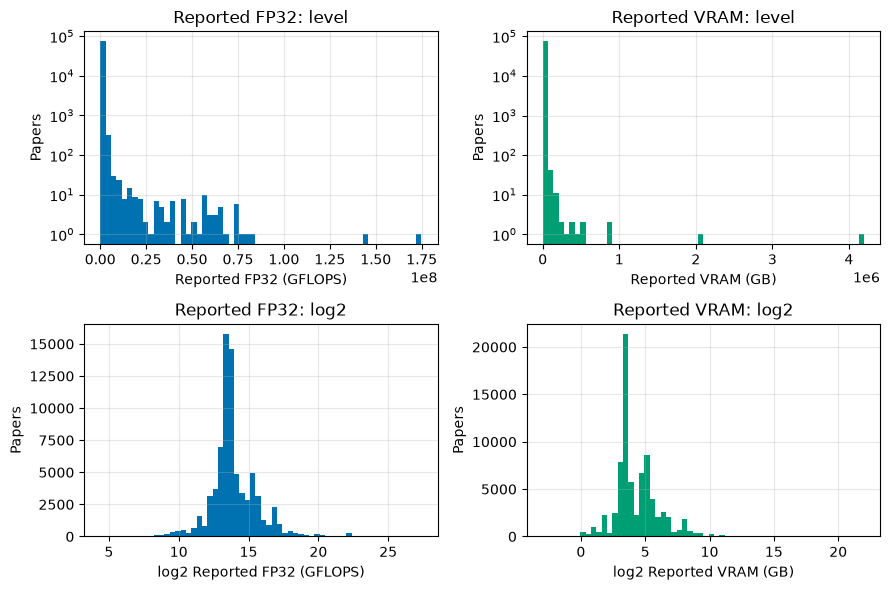

shape: (2, 6)
┌───────────────┬────────────┬───────────┬─────────┬──────────┬─────────────┐
│ axis          ┆ skew_level ┆ skew_log2 ┆ p50     ┆ p99      ┆ max         │
│ ---           ┆ ---        ┆ ---       ┆ ---     ┆ ---      ┆ ---         │
│ str           ┆ f64        ┆ f64       ┆ f64     ┆ f64      ┆ f64         │
╞═══════════════╪════════════╪═══════════╪═════════╪══════════╪═════════════╡
│ Reported FP32 ┆ 40.3       ┆ 1.07      ┆ 13448.0 ┆ 953600.0 ┆ 1.7485824e8 │
│ Reported VRAM ┆ 181.8      ┆ 1.49      ┆ 16.0    ┆ 1320.2   ┆ 4.196368e6  │
└───────────────┴────────────┴───────────┴─────────┴──────────┴─────────────┘
correlations (log2 scale)
shape: (6, 7)
┌─────────────┬─────────┬─────────┬─────────────┬─────────────┬────────────┬───────┐
│             ┆ l2_fp32 ┆ l2_vram ┆ l2_fp32_dev ┆ l2_vram_dev ┆ l2_devices ┆ y     │
│ ---         ┆ ---     ┆ ---     ┆ ---         ┆ ---         ┆ ---        ┆ ---   │
│ str         ┆ f64     ┆ f64     ┆ f64         ┆ f64         ┆ f64

In [5]:
skew = lambda v: float(((v - v.mean()) ** 3).mean() / v.std() ** 3)
# skew goes in the printed table, not the axes titles: `plotting.save_figure`
# names the exported PDF after the titles, so a number in a title puts the data
# in the filename and churns it on every re-run
rows_skew = []
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for j, (col, lab, cc) in enumerate([('reported_fp32_gflops', 'Reported FP32 (GFLOPS)', C_FP32),
                                    ('reported_vram_gb', 'Reported VRAM (GB)', C_VRAM)]):
    v = d[col].to_numpy()
    short = lab.split(' (')[0]
    axes[0][j].hist(v, bins=60, color=cc)
    axes[0][j].set(xlabel=lab, ylabel='Papers', yscale='log',
                   title=f'{short}: level')
    lv = np.log2(v)
    axes[1][j].hist(lv, bins=60, color=cc)
    axes[1][j].set(xlabel=f'log2 {lab}', ylabel='Papers', title=f'{short}: log2')
    rows_skew.append({'axis': short, 'skew_level': round(skew(v), 1),
                      'skew_log2': round(skew(lv), 2),
                      'p50': round(float(np.median(v)), 1),
                      'p99': round(float(np.quantile(v, 0.99)), 1),
                      'max': round(float(v.max()), 1)})
    for ax in (axes[0][j], axes[1][j]):
        ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(pl.DataFrame(rows_skew))
pairs = ['l2_fp32', 'l2_vram', 'l2_fp32_dev', 'l2_vram_dev', 'l2_devices', 'y']
mcor = np.corrcoef(np.column_stack([d[cc].to_numpy() for cc in pairs]).T)
print('correlations (log2 scale)')
print(pl.DataFrame({'': pairs, **{p_: [round(float(x), 3) for x in mcor[:, i]]
                                  for i, p_ in enumerate(pairs)}}))

## 9.2 Main specifications: citations per doubling of capacity

Every column carries **field + year fixed effects** and is estimated on the
identical sample, so differences across columns are specification, not sample.

*Three readings of the same estimate.* $\beta$ is a change in $\log(1+c^3)$ per
doubling; `pct` = $100(e^{\beta}-1)$ is that as a percentage change in $1+c^3$;
`d_cites` converts it to citations at the sample median (with the caveat stated
in the intro). Nothing is re-estimated between them.

*Standard errors* are clustered on field: the concern is that papers within a
field share unobserved citation norms and hardware regimes, which is a field-
level, not paper-level, dependency. There are only ~20 clusters, so the
clustered SEs are somewhat conservative and their small-sample behaviour is
imperfect; §9.8 reports HC1 and field x year clustering for comparison, and the
conclusions do not turn on the choice.

In [6]:
main = {
    'FP32 only': pf.feols(f'y ~ l2_fp32 | {FE}', data=P, vcov=CL),
    'VRAM only': pf.feols(f'y ~ l2_vram | {FE}', data=P, vcov=CL),
    'FP32 + VRAM': pf.feols(f'y ~ l2_fp32 + l2_vram | {FE}', data=P, vcov=CL),
    'devices only': pf.feols(f'y ~ l2_devices | {FE}', data=P, vcov=CL),
    'per-device FP32 + devices':
        pf.feols(f'y ~ l2_fp32_dev + l2_devices | {FE}', data=P, vcov=CL),
    'per-device VRAM + devices':
        pf.feols(f'y ~ l2_vram_dev + l2_devices | {FE}', data=P, vcov=CL),
}
tab_main = rg.stack(main).with_columns(
    d_cites=cites(pl.col('beta')), dc_lo=cites(pl.col('lo')),
    dc_hi=cites(pl.col('hi')))
with pl.Config(tbl_rows=30, tbl_width_chars=220):
    print(tab_main.select('spec', 'term', pl.col('beta').round(4),
                          pl.col('se').round(4), pl.col('p').round(4),
                          pl.col('pct').round(1), pl.col('d_cites').round(2),
                          pl.col('dc_lo').round(2), pl.col('dc_hi').round(2),
                          'n', pl.col('r2_within').round(4)))

m0 = main['FP32 only']
b, se = float(m0.coef()['l2_fp32']), float(m0.se()['l2_fp32'])
print(f'\nheadline: doubling reported FP32 is associated with '
      f'{100*(np.exp(b)-1):+.1f}% in (1 + 3-yr citations) '
      f'[95% CI {100*(np.exp(b-1.96*se)-1):+.1f}, {100*(np.exp(b+1.96*se)-1):+.1f}]'
      f', i.e. {cites(b):+.1f} citations for a paper at the sample median '
      f'({BASE:.0f} citations)')

shape: (9, 11)
┌───────────────────────────┬─────────────┬────────┬────────┬───┬───────┬───────┬───────┬───────────┐
│ spec                      ┆ term        ┆ beta   ┆ se     ┆ … ┆ dc_lo ┆ dc_hi ┆ n     ┆ r2_within │
│ ---                       ┆ ---         ┆ ---    ┆ ---    ┆   ┆ ---   ┆ ---   ┆ ---   ┆ ---       │
│ str                       ┆ str         ┆ f64    ┆ f64    ┆   ┆ f64   ┆ f64   ┆ i32   ┆ f64       │
╞═══════════════════════════╪═════════════╪════════╪════════╪═══╪═══════╪═══════╪═══════╪═══════════╡
│ FP32 only                 ┆ l2_fp32     ┆ 0.1133 ┆ 0.0188 ┆ … ┆ 1.08  ┆ 2.3   ┆ 76296 ┆ 0.0186    │
│ VRAM only                 ┆ l2_vram     ┆ 0.1124 ┆ 0.016  ┆ … ┆ 1.15  ┆ 2.19  ┆ 76296 ┆ 0.0212    │
│ FP32 + VRAM               ┆ l2_fp32     ┆ 0.0418 ┆ 0.0043 ┆ … ┆ 0.47  ┆ 0.73  ┆ 76296 ┆ 0.022     │
│ FP32 + VRAM               ┆ l2_vram     ┆ 0.0801 ┆ 0.015  ┆ … ┆ 0.7   ┆ 1.65  ┆ 76296 ┆ 0.022     │
│ devices only              ┆ l2_devices  ┆ 0.107  ┆ 0.019  ┆ … ┆ 0

## 9.3 The per-unit and per-SD readings

Three alternatives to "per doubling", for quoting in the text:

1. **Per GB / per TFLOP (level).** What "what is a 1 GB increase worth?"
   literally asks for. Reported three ways, because the answer depends entirely
   on where in the distribution you stand: untrimmed, trimmed at the `TRIM_Q`
   quantile, and restricted to the interquartile range. The spread across those
   three *is* the leverage warning — untrimmed, a handful of papers with
   thousands of GB flatten the slope to indistinguishable from zero. A
   linear-in-level coefficient is a poor summary of a variable spanning four
   orders of magnitude, which is why it is quoted here and used nowhere else.
2. **Per 10 GB / per 10 TFLOP**, the same coefficient at a more readable step.
3. **Per SD of log capacity** (`z_*`), which puts FP32 and VRAM on one scale and
   is the comparable magnitude when the two axes' units are not the point.

In [7]:
hi_fp32 = d['fp32_tflops'].quantile(TRIM_Q)
hi_vram = d['vram_gb'].quantile(TRIM_Q)
dt = d.filter((pl.col('fp32_tflops') <= hi_fp32) & (pl.col('vram_gb') <= hi_vram))
print(f'trim at q={TRIM_Q}: FP32 <= {hi_fp32:,.1f} TFLOPS, VRAM <= {hi_vram:,.0f} GB '
      f'-> {dt.height:,} of {d.height:,} papers ({100*dt.height/d.height:.1f}%)')
q1f, q3f = d['fp32_tflops'].quantile(0.25), d['fp32_tflops'].quantile(0.75)
q1v, q3v = d['vram_gb'].quantile(0.25), d['vram_gb'].quantile(0.75)
dq = d.filter(pl.col('fp32_tflops').is_between(q1f, q3f)
              & pl.col('vram_gb').is_between(q1v, q3v))
print(f'IQR box: FP32 {q1f:,.1f}-{q3f:,.1f} TFLOPS, VRAM {q1v:,.0f}-{q3v:,.0f} GB '
      f'-> {dq.height:,} papers ({100*dq.height/d.height:.1f}%)')
Pt, Pq = rg.to_pandas(dt, COLS), rg.to_pandas(dq, COLS)

units = {
    'per GB (untrimmed)': pf.feols(f'y ~ vram_gb | {FE}', data=P, vcov=CL),
    'per GB (trimmed)': pf.feols(f'y ~ vram_gb | {FE}', data=Pt, vcov=CL),
    'per GB (IQR only)': pf.feols(f'y ~ vram_gb | {FE}', data=Pq, vcov=CL),
    'per TFLOP (untrimmed)': pf.feols(f'y ~ fp32_tflops | {FE}', data=P, vcov=CL),
    'per TFLOP (trimmed)': pf.feols(f'y ~ fp32_tflops | {FE}', data=Pt, vcov=CL),
    'per TFLOP (IQR only)': pf.feols(f'y ~ fp32_tflops | {FE}', data=Pq, vcov=CL),
    'per SD of log2 FP32': pf.feols(f'y ~ z_fp32 | {FE}', data=P, vcov=CL),
    'per SD of log2 VRAM': pf.feols(f'y ~ z_vram | {FE}', data=P, vcov=CL),
}
with pl.Config(tbl_rows=20, tbl_width_chars=200):
    print(rg.stack(units).select('spec', 'term', pl.col('beta').round(6),
                                 pl.col('se').round(6), pl.col('p').round(4), 'n'))
for lab, key, unit in [('VRAM', 'per GB (trimmed)', 'GB'),
                       ('FP32', 'per TFLOP (trimmed)', 'TFLOP')]:
    bb = float(units[key].coef().iloc[0])
    print(f'{lab} (trimmed): {bb:+.5f} log points per {unit} '
          f'({100*bb:+.3f}% per {unit}; {100*10*bb:+.2f}% per 10 {unit}; '
          f'{cites(bb):+.3f} citations per {unit} at the median paper)')
print(f'\nfor scale, the sample SD of log2 FP32 is {d["l2_fp32"].std():.2f} '
      f'doublings and of log2 VRAM {d["l2_vram"].std():.2f} doublings')

trim at q=0.99: FP32 <= 953.6 TFLOPS, VRAM <= 1,320 GB -> 75,275 of 76,296 papers (98.7%)
IQR box: FP32 9.1-26.9 TFLOPS, VRAM 11-32 GB -> 33,777 papers (44.3%)


shape: (8, 6)
┌───────────────────────┬─────────────┬──────────┬──────────┬────────┬───────┐
│ spec                  ┆ term        ┆ beta     ┆ se       ┆ p      ┆ n     │
│ ---                   ┆ ---         ┆ ---      ┆ ---      ┆ ---    ┆ ---   │
│ str                   ┆ str         ┆ f64      ┆ f64      ┆ f64    ┆ i32   │
╞═══════════════════════╪═════════════╪══════════╪══════════╪════════╪═══════╡
│ per GB (untrimmed)    ┆ vram_gb     ┆ 0.0      ┆ 0.0      ┆ 0.9445 ┆ 76296 │
│ per GB (trimmed)      ┆ vram_gb     ┆ 0.001211 ┆ 0.000112 ┆ 0.0    ┆ 75275 │
│ per GB (IQR only)     ┆ vram_gb     ┆ 0.004202 ┆ 0.001761 ┆ 0.026  ┆ 33777 │
│ per TFLOP (untrimmed) ┆ fp32_tflops ┆ 0.000012 ┆ 0.000002 ┆ 0.0    ┆ 76296 │
│ per TFLOP (trimmed)   ┆ fp32_tflops ┆ 0.002514 ┆ 0.000215 ┆ 0.0    ┆ 75275 │
│ per TFLOP (IQR only)  ┆ fp32_tflops ┆ 0.002211 ┆ 0.002026 ┆ 0.287  ┆ 33777 │
│ per SD of log2 FP32   ┆ z_fp32      ┆ 0.197281 ┆ 0.032779 ┆ 0.0    ┆ 76296 │
│ per SD of log2 VRAM   ┆ z_vram      

## 9.4 Is it log-linear? Nonparametric dose-response

The single log-linear term is a functional-form assumption, and this is the test
of it: quantile bins of capacity as `C(bin)` dummies (lowest bin the reference),
same fixed effects, plotted against the bin's mean $\log_2$ capacity. If the log
form is adequate the bin coefficients lie on a straight line — the dashed line
is the fitted linear slope from §9.2, drawn from the same origin, so a
systematic departure is visible rather than inferred.

The right-hand axis is those same coefficients in **citations**, evaluated at
the reference bin's own median `i_3` (printed below): "how many more citations
than a typical lowest-capacity paper".

Bins are quantiles of a heavily tied distribution (VRAM piles up at 8/12/16/24
GB), so `allow_duplicates` can make them unequal in size; the counts and support
are printed so an odd-looking bin can be checked.

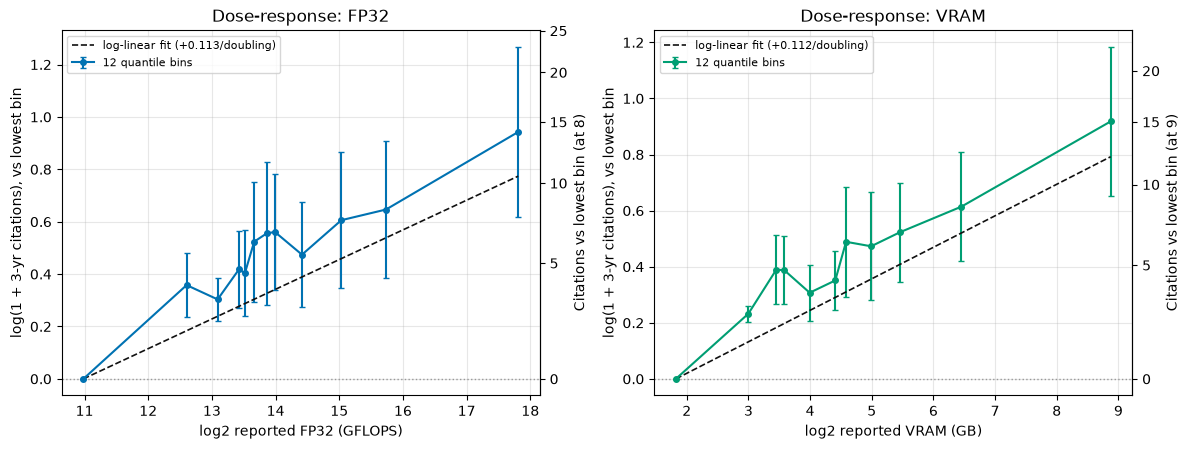

--- l2_fp32 (reference-bin median i_3 = 8) ---
shape: (12, 9)
┌─────┬───────┬───────┬───────┬───┬───────┬───────┬───────┬─────────┐
│ bin ┆ n_bin ┆ x_lo  ┆ x_hi  ┆ … ┆ beta  ┆ se    ┆ pct   ┆ d_cites │
│ --- ┆ ---   ┆ ---   ┆ ---   ┆   ┆ ---   ┆ ---   ┆ ---   ┆ ---     │
│ str ┆ u32   ┆ f64   ┆ f64   ┆   ┆ f64   ┆ f64   ┆ f64   ┆ f64     │
╞═════╪═══════╪═══════╪═══════╪═══╪═══════╪═══════╪═══════╪═════════╡
│ 00  ┆ 6506  ┆ 4.38  ┆ 12.1  ┆ … ┆ 0.0   ┆ 0.0   ┆ 0.0   ┆ 0.0     │
│ 01  ┆ 6324  ┆ 12.11 ┆ 12.87 ┆ … ┆ 0.358 ┆ 0.059 ┆ 43.0  ┆ 3.9     │
│ 02  ┆ 6244  ┆ 12.87 ┆ 13.15 ┆ … ┆ 0.303 ┆ 0.039 ┆ 35.4  ┆ 3.2     │
│ 03  ┆ 12418 ┆ 13.15 ┆ 13.47 ┆ … ┆ 0.418 ┆ 0.071 ┆ 51.9  ┆ 4.7     │
│ 04  ┆ 320   ┆ 13.47 ┆ 13.52 ┆ … ┆ 0.404 ┆ 0.079 ┆ 49.8  ┆ 4.5     │
│ 05  ┆ 9286  ┆ 13.52 ┆ 13.72 ┆ … ┆ 0.524 ┆ 0.111 ┆ 68.8  ┆ 6.2     │
│ 06  ┆ 8301  ┆ 13.72 ┆ 13.86 ┆ … ┆ 0.555 ┆ 0.131 ┆ 74.2  ┆ 6.7     │
│ 07  ┆ 2559  ┆ 13.87 ┆ 13.99 ┆ … ┆ 0.561 ┆ 0.107 ┆ 75.2  ┆ 6.8     │
│ 08  ┆ 5742  ┆ 13.99 ┆ 14.7

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
dose = {}
for ax, (col, lab, cc, key) in zip(
        axes, [('l2_fp32', 'log2 reported FP32 (GFLOPS)', C_FP32, 'FP32 only'),
               ('l2_vram', 'log2 reported VRAM (GB)', C_VRAM, 'VRAM only')]):
    binned, summary = rg.quantile_bins(d, col, N_BINS)
    m = pf.feols(f'y ~ C(bin) | {FE}', data=rg.to_pandas(binned, COLS + ['bin']),
                 vcov=CL)
    tab = rg.dose_table(m, summary)
    # baseline = the reference bin's own median, so the right axis reads
    # "citations above a typical lowest-bin paper"
    ref_base = float(binned.filter(pl.col('bin') == summary['bin'][0])[OUTCOME]
                     .median())
    dose[col] = (tab, ref_base)
    x, b = tab['x_mean'].to_numpy(), tab['beta'].to_numpy()
    ax.errorbar(x, b, yerr=[b - tab['lo'].to_numpy(), tab['hi'].to_numpy() - b],
                marker='o', ms=4, color=cc, lw=1.5, capsize=2,
                label=f'{N_BINS} quantile bins')
    slope = float(main[key].coef().iloc[0])
    ax.plot(x, slope * (x - x[0]), ls='--', color='#111111', lw=1.2,
            label=f'log-linear fit ({slope:+.3f}/doubling)')
    ax.axhline(0, color='#999999', lw=1, ls=':')
    short = 'FP32' if 'FP32' in lab else 'VRAM'
    ax.set(xlabel=lab, ylabel='log(1 + 3-yr citations), vs lowest bin',
           title=f'Dose-response: {short}')
    # the same estimates on a citation scale -- a monotone relabelling of the
    # left axis, not a second estimate. `rb=ref_base` binds the baseline NOW:
    # matplotlib calls these at draw time, after the loop has moved on, so a
    # closure over the loop variable would give both panels the last panel's
    # baseline.
    ax.secondary_yaxis(
        'right', functions=(lambda v, rb=ref_base: rg.delta_citations(v, rb),
                            lambda dc, rb=ref_base: np.log1p(
                                np.asarray(dc, dtype=float) / (1 + rb)))
    ).set_ylabel(f'Citations vs lowest bin (at {ref_base:.0f})')
    ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

with pl.Config(tbl_rows=30, tbl_width_chars=200):
    for col, (tab, ref_base) in dose.items():
        print(f'--- {col} (reference-bin median {OUTCOME} = {ref_base:.0f}) ---')
        print(tab.select('bin', 'n_bin', pl.col('x_lo').round(2),
                         pl.col('x_hi').round(2), pl.col('x_mean').round(2),
                         pl.col('beta').round(3), pl.col('se').round(3),
                         pl.col('pct').round(1),
                         d_cites=rg.delta_citations(pl.col('beta'), ref_base).round(1)))

## 9.5 Field interactions: which fields' citations respond most?

One regression per axis, `i(field_top, l2_capacity)`: pyfixest's `i()` omits no
reference level when it interacts with a continuous variable, so **every
coefficient is that field's own slope**, not a difference from a base field,
with field and year effects still absorbed. The printed Wald test is the joint
hypothesis that all field slopes are **equal** — the actual test of
heterogeneity, as opposed to eyeballing overlapping intervals.

Standard errors are clustered on field x year, not field. This is not a
preference: an interaction term confined to a single cluster has its score
zeroed by the regression's own first-order condition, so the cluster-robust SEs
come back as numerical noise — on this sample, Chemistry's slope had an SE of
0.005 and the heterogeneity chi2 came out at 5.5 **million**, versus 0.021 and
63 once clustered finer. pyfixest fits that specification happily and warns
about nothing, so `regress.assert_cluster_finer` is called explicitly before
each interaction model.

Both panels are drawn in **citations**, converted at the sample median, on one
shared range (`CITE_LIM`, the image of `SLOPE_LIM` — the same range §9.6 uses on
its y axis). So FP32 vs VRAM, and this figure vs §9.6, are read off a single
scale in a single unit; the log-point estimates behind the axis are in the table
below, along with each field's **own**-median conversion (`d_cites`), which is
the more accurate per-field number but cannot be an axis because every field
would need a different one. Comparing `beta` across fields compares
responsiveness; comparing `d_cites` compares responsiveness *and* citation
baseline together, which is the more policy-relevant number and the less clean
estimand.

**Computer Science is most of this sample**, so the pooled §9.2 estimate is
largely a CS estimate — the share is printed below. That is itself a finding
about where reported compute lives, but it means the pooled coefficient should
not be read as an average over fields.

A field's slope is not a field's "return to compute": fields differ in what
compute is used *for*, in citation norms (absorbed in level, not in slope), and
in how much of their capacity variation is real rather than reporting practice.
A steeper slope means citations are more strongly graded by reported capacity
within that field.

FP32: slopes equal across fields?  chi2(8) = 66.2, p = 2.81e-11


VRAM: slopes equal across fields?  chi2(8) = 97.2, p = 1.61e-17


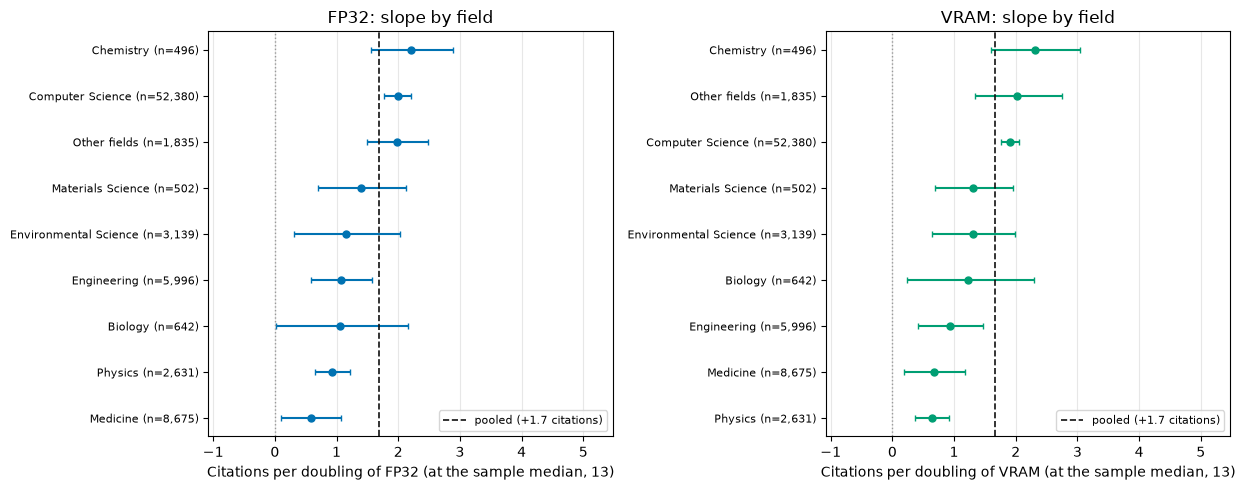


Computer Science: 52,380 of 76,296 papers (69% of the sample)
--- FP32 slope by field (d_cites at each field own median) ---
shape: (9, 8)
┌───────────────────────┬─────────┬───────────┬───────┬───────┬────────┬──────┬─────────┐
│ level                 ┆ n_group ┆ med_cites ┆ beta  ┆ se    ┆ p      ┆ pct  ┆ d_cites │
│ ---                   ┆ ---     ┆ ---       ┆ ---   ┆ ---   ┆ ---    ┆ ---  ┆ ---     │
│ str                   ┆ u32     ┆ f64       ┆ f64   ┆ f64   ┆ f64    ┆ f64  ┆ f64     │
╞═══════════════════════╪═════════╪═══════════╪═══════╪═══════╪════════╪══════╪═════════╡
│ Chemistry             ┆ 496     ┆ 15.0      ┆ 0.146 ┆ 0.021 ┆ 0.0    ┆ 15.8 ┆ 2.52    │
│ Computer Science      ┆ 52380   ┆ 13.0      ┆ 0.133 ┆ 0.007 ┆ 0.0    ┆ 14.2 ┆ 1.99    │
│ Other fields          ┆ 1835    ┆ 11.0      ┆ 0.132 ┆ 0.016 ┆ 0.0    ┆ 14.1 ┆ 1.7     │
│ Materials Science     ┆ 502     ┆ 11.0      ┆ 0.095 ┆ 0.023 ┆ 0.0001 ┆ 10.0 ┆ 1.2     │
│ Environmental Science ┆ 3139    ┆ 15.0      ┆ 0.

In [9]:
rg.assert_cluster_finer(d, 'field_top', 'field_year')
fmed = (d.group_by('field_top').agg(n_group=pl.len(),
                                    med_cites=pl.col(OUTCOME).median())
        .rename({'field_top': 'level'}))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), sharex=True)
field_tabs = {}
for ax, (col, lab, cc, key) in zip(
        axes, [('l2_fp32', 'FP32', C_FP32, 'FP32 only'),
               ('l2_vram', 'VRAM', C_VRAM, 'VRAM only')]):
    m = pf.feols(f'y ~ i(field_top, {col}) | field_top + year_f', data=P,
                 vcov=CL_INT)
    tab = (rg.slopes(m, 'field_top', col).join(fmed, on='level', how='left')
           .with_columns(d_cites=rg.delta_citations(pl.col('beta'),
                                                    pl.col('med_cites')),
                         dc_lo=rg.delta_citations(pl.col('lo'), pl.col('med_cites')),
                         dc_hi=rg.delta_citations(pl.col('hi'), pl.col('med_cites')))
           .sort('beta'))
    field_tabs[lab] = tab
    assert tab['lo'].min() >= SLOPE_LIM[0] and tab['hi'].max() <= SLOPE_LIM[1], \
        f'{lab}: a field CI falls outside SLOPE_LIM -- widen it, do not clip'
    # plotted in citations, converted at the SAMPLE median so every panel (and
    # §9.6) shares one scale. The conversion is monotone, so converting the CI
    # endpoints gives that interval's exact image -- asymmetric around the point
    # estimate, which is why xerr is passed as two arrays.
    ypos = np.arange(tab.height)
    dc = cites(tab['beta'].to_numpy())
    dlo, dhi = cites(tab['lo'].to_numpy()), cites(tab['hi'].to_numpy())
    ax.errorbar(dc, ypos, xerr=[dc - dlo, dhi - dc],
                fmt='o', ms=5, color=cc, capsize=2, lw=1.5)
    pooled = cites(float(main[key].coef().iloc[0]))
    ax.axvline(pooled, color='#111111', lw=1.2, ls='--',
               label=f'pooled ({pooled:+.1f} citations)')
    ax.axvline(0, color='#999999', lw=1, ls=':')
    ax.set_yticks(ypos)
    ax.set_yticklabels([f'{g} (n={n:,})' for g, n in
                        zip(tab['level'], tab['n_group'])], fontsize=8)
    ax.set(xlabel=f'Citations per doubling of {lab} '
                  f'(at the sample median, {BASE:.0f})',
           title=f'{lab}: slope by field', xlim=CITE_LIM)
    ax.legend(fontsize=8, loc='lower right'); ax.grid(alpha=0.3, axis='x')
    stat, dfree, p = rg.equality_test(m)
    print(f'{lab}: slopes equal across fields?  chi2({dfree}) = {stat:.1f}, '
          f'p = {p:.2e}')
plt.tight_layout(); plt.show()

cs = d.filter(pl.col('field') == 'Computer Science').height
print(f'\nComputer Science: {cs:,} of {d.height:,} papers '
      f'({100*cs/d.height:.0f}% of the sample)')
with pl.Config(tbl_rows=30, tbl_width_chars=200):
    for lab, tab in field_tabs.items():
        print(f'--- {lab} slope by field (d_cites at each field own median) ---')
        print(tab.select('level', 'n_group', 'med_cites', pl.col('beta').round(3),
                         pl.col('se').round(3), pl.col('p').round(4),
                         pl.col('pct').round(1), pl.col('d_cites').round(2))
              .sort('beta', descending=True))

## 9.6 Has the return changed over time?

The same interaction with `year_f` as the group: one slope per publication year,
field and year effects still absorbed, clustered on field x year for the reason
given in §9.5. Years resting on fewer than `MIN_YEAR_N` papers are flagged in
the output.

The y axis here and the x axis in §9.5 are the **same quantity, in the same
unit, on the same range** — citations per doubling at the sample median — so the
spread of slopes across fields and across years can be compared by eye. Both
cells assert that no confidence interval falls outside the shared range, so it
can never clip silently. The underlying log-point coefficients are in the table.

The citation *level* also drifts across this window, which a fixed sample-median
axis deliberately holds still. The per-year conversion at each year's own median
(`d_cites` in the table below) is the "citations per doubling" a paper of that
year would actually have seen; it can move even where the slope is flat, and it
is a table column rather than an axis because its baseline changes every year.

Compute also got cheaper and more common over this window (§5), so a falling
slope says capacity is a weaker *discriminator* between papers, not that compute
became less useful.

FP32: slopes equal across years?  chi2(12) = 64.3, p = 3.63e-09
FP32: thin years (< MIN_YEAR_N=300 papers), slopes shown but noisy: 2010, 2011, 2012


VRAM: slopes equal across years?  chi2(12) = 111.3, p = 3.23e-18
VRAM: thin years (< MIN_YEAR_N=300 papers), slopes shown but noisy: 2010, 2011, 2012


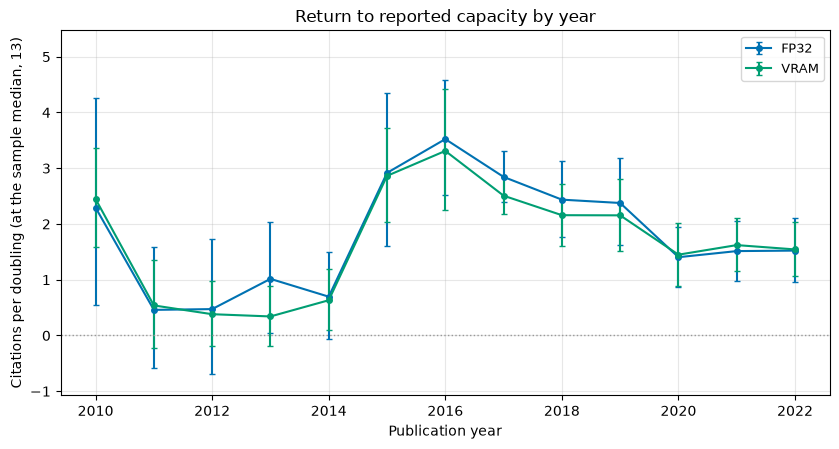

shape: (13, 6)
┌───────┬─────────┬───────────┬───────┬───────┬─────────┐
│ level ┆ n_group ┆ med_cites ┆ beta  ┆ se    ┆ d_cites │
│ ---   ┆ ---     ┆ ---       ┆ ---   ┆ ---   ┆ ---     │
│ str   ┆ u32     ┆ f64       ┆ f64   ┆ f64   ┆ f64     │
╞═══════╪═════════╪═══════════╪═══════╪═══════╪═════════╡
│ 2010  ┆ 138     ┆ 9.0       ┆ 0.152 ┆ 0.058 ┆ 1.64    │
│ 2011  ┆ 185     ┆ 8.0       ┆ 0.032 ┆ 0.038 ┆ 0.3     │
│ 2012  ┆ 250     ┆ 6.0       ┆ 0.033 ┆ 0.043 ┆ 0.24    │
│ 2013  ┆ 312     ┆ 7.0       ┆ 0.07  ┆ 0.034 ┆ 0.58    │
│ 2014  ┆ 406     ┆ 7.0       ┆ 0.049 ┆ 0.027 ┆ 0.4     │
│ 2015  ┆ 571     ┆ 11.0      ┆ 0.189 ┆ 0.041 ┆ 2.5     │
│ 2016  ┆ 948     ┆ 16.0      ┆ 0.224 ┆ 0.03  ┆ 4.28    │
│ 2017  ┆ 2136    ┆ 18.0      ┆ 0.185 ┆ 0.014 ┆ 3.86    │
│ 2018  ┆ 4497    ┆ 17.0      ┆ 0.16  ┆ 0.021 ┆ 3.13    │
│ 2019  ┆ 8003    ┆ 15.0      ┆ 0.157 ┆ 0.024 ┆ 2.72    │
│ 2020  ┆ 14865   ┆ 13.0      ┆ 0.096 ┆ 0.018 ┆ 1.4     │
│ 2021  ┆ 20413   ┆ 13.0      ┆ 0.103 ┆ 0.018 ┆ 1.51    │

In [10]:
rg.assert_cluster_finer(d, 'year_f', 'field_year')
ymed = (d.group_by('year_f').agg(n_group=pl.len(),
                                 med_cites=pl.col(OUTCOME).median())
        .rename({'year_f': 'level'}))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
time_tabs = {}
for col, lab, cc in [('l2_fp32', 'FP32', C_FP32), ('l2_vram', 'VRAM', C_VRAM)]:
    m = pf.feols(f'y ~ i(year_f, {col}) | {FE}', data=P, vcov=CL_INT)
    tab = (rg.slopes(m, 'year_f', col).join(ymed, on='level', how='left')
           .with_columns(yr=pl.col('level').cast(pl.Int32),
                         d_cites=rg.delta_citations(pl.col('beta'),
                                                    pl.col('med_cites')),
                         dc_lo=rg.delta_citations(pl.col('lo'), pl.col('med_cites')),
                         dc_hi=rg.delta_citations(pl.col('hi'), pl.col('med_cites')))
           .sort('yr'))
    time_tabs[lab] = tab
    stat, dfree, p = rg.equality_test(m)
    print(f'{lab}: slopes equal across years?  chi2({dfree}) = {stat:.1f}, p = {p:.2e}')
    thin = tab.filter(pl.col('n_group') < MIN_YEAR_N)['level'].to_list()
    if thin:
        print(f'{lab}: thin years (< MIN_YEAR_N={MIN_YEAR_N} papers), '
              f'slopes shown but noisy: {", ".join(thin)}')
    assert tab['lo'].min() >= SLOPE_LIM[0] and tab['hi'].max() <= SLOPE_LIM[1], \
        f'{lab}: a year CI falls outside SLOPE_LIM -- widen it, do not clip'
    # citations at the SAMPLE median, the same scale §9.5 uses on its x axis
    dc = cites(tab['beta'].to_numpy())
    dlo, dhi = cites(tab['lo'].to_numpy()), cites(tab['hi'].to_numpy())
    ax.errorbar(tab['yr'].to_numpy(), dc, yerr=[dc - dlo, dhi - dc],
                marker='o', ms=4, color=cc, capsize=2, lw=1.5, label=lab)
ax.axhline(0, color='#999999', lw=1, ls=':')
ax.set(xlabel='Publication year', ylim=CITE_LIM,
       ylabel=f'Citations per doubling (at the sample median, {BASE:.0f})',
       title='Return to reported capacity by year')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

with pl.Config(tbl_rows=30, tbl_width_chars=200):
    print(time_tabs['FP32'].select('level', 'n_group', 'med_cites',
                                   pl.col('beta').round(3), pl.col('se').round(3),
                                   pl.col('d_cites').round(2)))

## 9.7 What survives controls, and where the association comes from

Two questions, both about interpretation rather than precision.

**How much is compute, how much is the paper around it?** Bigger-compute papers
have bigger teams and longer reference lists, and both predict citations for
reasons that have nothing to do with hardware. Adding `log(1+authors)` and
`log(1+references)` does not identify a causal effect — they are outcomes of the
same resourcing — but the *attenuation* bounds how much of the raw association
is carried by observable correlates of project scale. Treat the controlled
coefficient as a lower bound and the uncontrolled one as an upper bound.

**Better chips or more of them?** `l2_fp32 = l2_fp32_dev + l2_devices` is an
identity, so entering the pieces separately splits the doubling into "double the
per-device capability" and "double the device count". These are different
economic objects: the first is a hardware generation, the second is a budget.

In [11]:
ctrl = ' + log_authors + log_refs' if WITH_CONTROLS else ''
models = {}
for col, lab in [('l2_fp32', 'FP32'), ('l2_vram', 'VRAM')]:
    models[f'{lab} raw'] = pf.feols(f'y ~ {col} | {FE}', data=P, vcov=CL)
    if ctrl:
        models[f'{lab} + team/refs'] = pf.feols(f'y ~ {col}{ctrl} | {FE}',
                                                data=P, vcov=CL)
models['per-device FP32 + devices + controls'] = pf.feols(
    f'y ~ l2_fp32_dev + l2_devices{ctrl} | {FE}', data=P, vcov=CL)
tab_ctrl = rg.stack(models).with_columns(d_cites=cites(pl.col('beta')))
with pl.Config(tbl_rows=30, tbl_width_chars=210):
    print(tab_ctrl.select('spec', 'term', pl.col('beta').round(4),
                          pl.col('se').round(4), pl.col('p').round(4),
                          pl.col('pct').round(1), pl.col('d_cites').round(2),
                          'n', pl.col('r2_within').round(4)))
if ctrl:
    for lab in ('FP32', 'VRAM'):
        col = 'l2_fp32' if lab == 'FP32' else 'l2_vram'
        b0 = float(models[f'{lab} raw'].coef()[col])
        b1 = float(models[f'{lab} + team/refs'].coef()[col])
        print(f'{lab}: {b0:+.4f} -> {b1:+.4f} with team size and reference count '
              f'({100*(1-b1/b0):.0f}% attenuation; '
              f'{cites(b0):+.1f} -> {cites(b1):+.1f} citations at the median)')

shape: (12, 9)
┌─────────────────────────────────┬─────────────┬────────┬────────┬───┬───────┬─────────┬───────┬───────────┐
│ spec                            ┆ term        ┆ beta   ┆ se     ┆ … ┆ pct   ┆ d_cites ┆ n     ┆ r2_within │
│ ---                             ┆ ---         ┆ ---    ┆ ---    ┆   ┆ ---   ┆ ---     ┆ ---   ┆ ---       │
│ str                             ┆ str         ┆ f64    ┆ f64    ┆   ┆ f64   ┆ f64     ┆ i32   ┆ f64       │
╞═════════════════════════════════╪═════════════╪════════╪════════╪═══╪═══════╪═════════╪═══════╪═══════════╡
│ FP32 raw                        ┆ l2_fp32     ┆ 0.1133 ┆ 0.0188 ┆ … ┆ 12.0  ┆ 1.68    ┆ 76296 ┆ 0.0186    │
│ FP32 + team/refs                ┆ l2_fp32     ┆ 0.0859 ┆ 0.0094 ┆ … ┆ 9.0   ┆ 1.26    ┆ 76296 ┆ 0.129     │
│ FP32 + team/refs                ┆ log_authors ┆ 0.4634 ┆ 0.0989 ┆ … ┆ 58.9  ┆ 8.25    ┆ 76296 ┆ 0.129     │
│ FP32 + team/refs                ┆ log_refs    ┆ 0.7463 ┆ 0.0658 ┆ … ┆ 110.9 ┆ 15.53   ┆ 76296 ┆ 0.129  

## 9.8 Robustness

Each row changes exactly one thing about the headline FP32 and VRAM
specifications. The headline is robust if the sign and rough magnitude hold; the
rows are not all equally informative, so what each one buys is stated:

- **field x year FE** — absorbs field-specific time trends, i.e. the possibility
  that the association is fields adopting compute at the same time as their
  citation norms shift. pyfixest drops singleton cells here (a field-year with
  one paper contributes nothing once its own effect is fitted), so `n` falls
  slightly; that is correct behaviour rather than a sample change to worry about.
- **HC1 / cluster field x year** — inference only, no change to $\beta$.
- **PPML** (`pf.fepois`) — the estimand check. Poisson pseudo-ML on the count
  itself, no `log1p`, so the coefficient is a semi-elasticity of citations
  rather than of $1+$citations. Expect it to come out **larger** than the log1p
  coefficient rather than equal: PPML's conditional-mean target weights papers
  by their citation counts, where the log transform pulls the high-citation tail
  in. The two answer different questions — "how does the mean move" versus "how
  does the typical paper move" — so the check is agreement in sign and rough
  scale, and the gap between them is worth reporting rather than hiding.
- **within field-year percentile rank** — replaces the outcome with the paper's
  rank among same-field, same-year papers (0-1). Immune to the citation
  distribution's skew and to any log transform at all. Its coefficient is in
  **percentile points per doubling**, so neither `pct` nor the citation
  conversion applies to that row and both are left null.
- **`i_5`, years <= 2020** — a longer window on the sub-sample whose 5-year
  window is closed.
- **explicit device counts** — the `explicit` count policy, dropping the floor-1
  imputation for papers that never state a count. This is the measurement-error
  check on the device-count factor.
- **per-axis sample** — drops the "spec on both axes" requirement.
- **trimmed** — leverage check.

In [12]:
d = d.with_columns(
    rank_fy=(pl.col(OUTCOME).rank('average').over('field', 'year_f') - 1)
    / pl.max_horizontal(pl.len().over('field', 'year_f') - 1, pl.lit(1)),
    y5=(1 + pl.col('citations_5y')).log())
RCOLS = COLS + ['rank_fy', 'y5']
P = rg.to_pandas(d, RCOLS)
P5 = rg.to_pandas(d.filter((pl.col('year') <= 2020)
                           & pl.col('citations_5y').is_not_null()), RCOLS)

# per-axis sample: drop the "spec on both axes" requirement
per_axis = (raw.filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX)
                       & pl.col(OUTCOME).is_not_null()
                       & pl.col('field').is_not_null())
            .with_columns(y=(1 + pl.col(OUTCOME)).log(),
                          year_f=pl.col('year').cast(pl.String)))
PA = {}
for col, gcol, flag in [('l2_fp32', 'reported_fp32_gflops', 'spec_missing_fp32'),
                        ('l2_vram', 'reported_vram_gb', 'spec_missing_vram')]:
    PA[col] = rg.to_pandas(
        per_axis.filter(~pl.col(flag) & (pl.col(gcol) > 0))
        .with_columns(**{col: pl.col(gcol).log(2)}), ['y', col, 'field', 'year_f'])

# explicit device counts: a different capacity table, everything else identical
cap_x = pl.read_parquet(
    s3_uri(capacity_key(c, reg.version, PROMPT_VERSION, MODEL_TAG, 'explicit')),
    storage_options=so)
PX = rg.to_pandas(
    cap_x.join(cit, on=KEY, how='left').join(meta, on=KEY, how='left')
    .filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX)
            & pl.col(OUTCOME).is_not_null() & pl.col('field').is_not_null()
            & ~pl.col('spec_missing_fp32') & ~pl.col('spec_missing_vram')
            & (pl.col('reported_fp32_gflops') > 0) & (pl.col('reported_vram_gb') > 0))
    .with_columns(y=(1 + pl.col(OUTCOME)).log(),
                  year_f=pl.col('year').cast(pl.String),
                  l2_fp32=pl.col('reported_fp32_gflops').log(2),
                  l2_vram=pl.col('reported_vram_gb').log(2)),
    ['y', 'l2_fp32', 'l2_vram', 'field', 'year_f'])

rows = []
for col in ('l2_fp32', 'l2_vram'):
    # (model, is the outcome on a log scale -> do pct/citation readings apply)
    variants = {
        'headline (field + year FE)': (pf.feols(f'y ~ {col} | {FE}', data=P, vcov=CL), True),
        'field x year FE': (pf.feols(f'y ~ {col} | field_year', data=P, vcov=CL), True),
        'HC1 SEs': (pf.feols(f'y ~ {col} | {FE}', data=P, vcov='hetero'), True),
        'cluster field x year': (pf.feols(f'y ~ {col} | {FE}', data=P, vcov=CL_INT), True),
        'PPML on the count': (pf.fepois(f'{OUTCOME} ~ {col} | {FE}', data=P, vcov=CL), True),
        f'trimmed at q={TRIM_Q}': (pf.feols(f'y ~ {col} | {FE}', data=Pt, vcov=CL), True),
        'outcome: within field-year rank':
            (pf.feols(f'rank_fy ~ {col} | {FE}', data=P, vcov=CL), False),
        'outcome: i_5, years <= 2020':
            (pf.feols(f'y5 ~ {col} | {FE}', data=P5, vcov=CL), True),
        'per-axis sample': (pf.feols(f'y ~ {col} | {FE}', data=PA[col], vcov=CL), True),
        'explicit device counts': (pf.feols(f'y ~ {col} | {FE}', data=PX, vcov=CL), True),
    }
    for lab, (m, on_log) in variants.items():
        t = rg.tidy(m, keep=[col], label=lab, pct=on_log).with_columns(
            axis=pl.lit(col))
        if on_log:
            t = t.with_columns(d_cites=cites(pl.col('beta')))
        rows.append(t)
rob = pl.concat(rows, how='diagonal')
with pl.Config(tbl_rows=60, tbl_width_chars=210):
    for col in ('l2_fp32', 'l2_vram'):
        print(f'--- {col} ---')
        print(rob.filter(pl.col('axis') == col)
              .select('spec', pl.col('beta').round(4), pl.col('se').round(4),
                      pl.col('pct').round(1), pl.col('d_cites').round(2),
                      'n', 'cluster'))

/users/6/gebhart/.conda/envs/accelscan/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 21 singleton fixed effect(s) dropped from the model.
  warnings.warn(


/users/6/gebhart/.conda/envs/accelscan/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 21 singleton fixed effect(s) dropped from the model.
  warnings.warn(


--- l2_fp32 ---
shape: (10, 7)
┌─────────────────────────────────┬────────┬────────┬──────┬─────────┬───────┬────────────────────────────────┐
│ spec                            ┆ beta   ┆ se     ┆ pct  ┆ d_cites ┆ n     ┆ cluster                        │
│ ---                             ┆ ---    ┆ ---    ┆ ---  ┆ ---     ┆ ---   ┆ ---                            │
│ str                             ┆ f64    ┆ f64    ┆ f64  ┆ f64     ┆ i32   ┆ str                            │
╞═════════════════════════════════╪════════╪════════╪══════╪═════════╪═══════╪════════════════════════════════╡
│ headline (field + year FE)      ┆ 0.1133 ┆ 0.0188 ┆ 12.0 ┆ 1.68    ┆ 76296 ┆ CRV1 field (23 clusters)       │
│ field x year FE                 ┆ 0.1127 ┆ 0.0193 ┆ 11.9 ┆ 1.67    ┆ 76275 ┆ CRV1 field (23 clusters)       │
│ HC1 SEs                         ┆ 0.1133 ┆ 0.0034 ┆ 12.0 ┆ 1.68    ┆ 76296 ┆ hetero                         │
│ cluster field x year            ┆ 0.1133 ┆ 0.0087 ┆ 12.0 ┆ 1.68    ┆ 76

## Caveats

1. **Not causal, and the confounding is not incidental.** Reported capacity is a
   choice made by resourced authors on visible problems. Field and year effects
   remove between-field and between-year confounding only; everything that
   varies *within* a field-year — institution, funding, venue, team quality,
   topic salience — is in the error term and is positively correlated with both
   compute and citations. §9.7's attenuation under team-size and reference
   controls is a bound, not a fix.
2. **Nameplate peak, not utilized FLOPs** (the §5 caveat). Also a *reported*
   quantity: the regressor is partly a measure of reporting practice, and
   reporting specificity itself rose sharply over this window (§4).
3. **The citation conversion is evaluated at a point, not averaged.** `d_cites`
   and the figures' citation axes apply $(1+\bar{c})(e^\beta-1)$ at a stated
   median. Effects are proportional, so a heavily-cited paper's implied gain is
   much larger and a barely-cited paper's much smaller; the number is "what this
   means for a typical paper", not an average treatment effect in citations.
   The regressand is `log1p` in every specification — nothing was re-estimated
   in citation units.
4. **The sample is accelerator-reporting papers with resolvable specs**, not
   science. Papers whose used models lack a spec are excluded per axis (never
   zero-filled), and spec coverage drifts across eras — see §5's coverage
   figure before extrapolating.
5. **`log1p` is not `log`.** With 5% of the sample at zero citations, the
   coefficient is a semi-elasticity of $1+c$; the PPML row in §9.8 is the
   estimand that has no such wrinkle.
6. **Device counts are imputed at 1 when unstated** under `floor1`, so
   `l2_devices` carries measurement error, which attenuates its coefficient and
   pushes the pooled capacity coefficient toward the per-device component. The
   `explicit` row in §9.8 is the sensitivity check.
7. **~20 field clusters.** Cluster-robust inference with this few clusters is
   approximate; the reported p-values are not to be read at three decimal
   places.
8. **Field is the first `s2fieldsofstudy` category** — a coarse, sometimes
   arbitrary label, and a paper's assignment can be wrong. Interaction estimates
   inherit that noise.